# Yambda 08 · SASRec (sequential Transformer) — runs on Google Colab GPU

**Before running**
1. `colab_bundle.zip` is uploaded to Google Drive at `MyDrive/music_recsys/colab_bundle.zip`.
2. Runtime → Change runtime type → **T4 GPU**.

Model code: `src/musicrec/models/sasrec.py`. Everything is evaluated with the same
`evaluate()` and validation split as iALS/BPR, so the numbers are directly comparable.
Outputs (results, curves, model weights) are copied back to `MyDrive/music_recsys/outputs/`
in the last cell, because Colab's own disk is wiped when the session ends.

In [3]:
# Setup: mount Drive, unpack code + data onto Colab's fast local disk
from google.colab import drive
drive.mount("/content/drive")
DRIVE = "/content/drive/MyDrive/music_recsys"
!rm -rf /content/music_recsys && mkdir -p /content/music_recsys
!unzip -q "{DRIVE}/colab_bundle.zip" -d /content/music_recsys

import sys
sys.path.insert(0, "/content/music_recsys/src")      # makes `import musicrec` work, no install needed
import torch
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE (switch runtime!)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
torch 2.11.0+cu130 | GPU: Tesla T4


In [4]:
import json, time
import pandas as pd
import matplotlib.pyplot as plt
from musicrec import config
from musicrec.preprocess import Split
from musicrec.evaluation import evaluate, paired_bootstrap, artist_novelty
from musicrec.yambda import load_item_artist
from musicrec.models.sasrec import SASRec

pd.set_option("display.float_format", "{:,.4f}".format)
split = Split.load(config.YAMBDA_SPLIT_VAL_DIR)
OUT = config.PROJECT_ROOT / "reports" / "yambda"
config.YAMBDA_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Per-user validation scores of the reference models, computed locally (no need to refit here)
ref = {k: pd.read_parquet(OUT / f"per_user_val_{k}.parquet") for k in ["pop7d", "ials", "bpr"]}
print({k: round(v["recall@10"].mean(), 4) for k, v in ref.items()})

{'pop7d': np.float64(0.0235), 'ials': np.float64(0.0346), 'bpr': np.float64(0.0334)}


## Train SASRec

One "epoch" = 400 steps × 128 user windows; validation after every epoch, early stopping with
patience 3. Expect roughly 20-40 s per epoch on a T4.

In [5]:
sas = SASRec(dim=128, max_len=200, n_layers=2, n_heads=2, dropout=0.2, lr=1e-3,
             batch_size=128, n_neg=2048, p_last=0.5, steps_per_epoch=400, epochs=30, patience=3)
print(sas.name, "| device:", sas.device)
t = time.time(); sas.fit(split); print(f"total {time.time() - t:.0f}s, best epoch {sas.best_epoch_}")
res = evaluate(sas, split, return_per_user=True)
print({k: round(v, 4) for k, v in res.items() if k != "per_user"})

SASRec(d=128, L=200, layers=2, neg=2048, p_last=0.5) | device: cuda
epoch  1  loss=6.5209  (36s)  val recall@10=0.0036
epoch  2  loss=6.0119  (35s)  val recall@10=0.0037
epoch  3  loss=5.6225  (36s)  val recall@10=0.0073
epoch  4  loss=5.1832  (37s)  val recall@10=0.0101
epoch  5  loss=4.7468  (37s)  val recall@10=0.0122
epoch  6  loss=4.3752  (37s)  val recall@10=0.0163
epoch  7  loss=4.0965  (37s)  val recall@10=0.0181
epoch  8  loss=3.8796  (37s)  val recall@10=0.0223
epoch  9  loss=3.6932  (37s)  val recall@10=0.0239
epoch 10  loss=3.5478  (37s)  val recall@10=0.0240
epoch 11  loss=3.4229  (37s)  val recall@10=0.0266
epoch 12  loss=3.3301  (37s)  val recall@10=0.0268
epoch 13  loss=3.2372  (36s)  val recall@10=0.0252
epoch 14  loss=3.1552  (38s)  val recall@10=0.0260
epoch 15  loss=3.0895  (37s)  val recall@10=0.0254
early stop: no improvement in 3 epochs
total 741s, best epoch 12
{'recall@10': 0.0268, 'ndcg@10': 0.0257, 'hit_rate@10': 0.1305, 'recall@50': 0.0494, 'ndcg@50': 0.0325

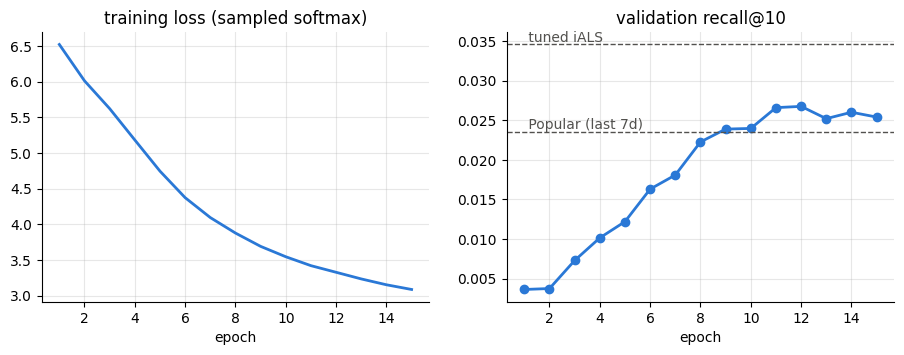

In [6]:
BLUE, GRAY = "#2a78d6", "#52514e"
h = pd.DataFrame(sas.history_)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(h["epoch"], h["loss"], color=BLUE, lw=2)
axes[1].plot(h["epoch"], h["val_recall@10"], color=BLUE, lw=2, marker="o")
for key, label in [("ials", "tuned iALS"), ("pop7d", "Popular (last 7d)")]:
    y = ref[key]["recall@10"].mean()
    axes[1].axhline(y, color=GRAY, lw=1, ls="--"); axes[1].text(1, y, f" {label}", va="bottom", color=GRAY)
axes[0].set(title="training loss (sampled softmax)", xlabel="epoch")
axes[1].set(title="validation recall@10", xlabel="epoch")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
fig.savefig(config.YAMBDA_FIGURES_DIR / "y08_sasrec_curves.png", dpi=150, bbox_inches="tight")

## Comparison with popularity, iALS and BPR (paired bootstrap over the same users)

In [7]:
mine = res["per_user"]
pd.DataFrame({f"SASRec vs {k}": paired_bootstrap(v, mine) for k, v in ref.items()}).T[
    ["a", "b", "diff", "rel_diff", "ci_low", "ci_high", "p(b<=a)"]]

,a,b,diff,rel_diff,ci_low,ci_high,p(b<=a)
SASRec vs pop7d,0.0235,0.0268,0.0033,0.1394,-0.0000,0.0063,0.0275
SASRec vs ials,0.0346,0.0268,-0.0078,-0.2263,-0.0108,-0.0049,1.0000
SASRec vs bpr,0.0334,0.0268,-0.0066,-0.1981,-0.0099,-0.0035,1.0000


## Familiar vs. new artists (SASRec only; iALS numbers come from notebook 04/06 locally)

In [8]:
item_artist = load_item_artist()
new_artist = artist_novelty(split, item_artist)
seg = {label: evaluate(sas, split, targets=split.targets[mask])["recall@10"]
       for label, mask in [("known-artist targets", ~new_artist), ("new-artist targets", new_artist)]}
seg

{'known-artist targets': 0.025269351383239668,
 'new-artist targets': 0.015223875594879015}

In [9]:
# Save everything and copy it back to Google Drive
torch.save({"state_dict": sas.module_.state_dict(), "params": sas.params(), "best_epoch": sas.best_epoch_},
           OUT / "sasrec_val.pt")
mine.to_parquet(OUT / "per_user_val_sasrec.parquet", index=False)
pd.DataFrame(sas.history_).to_csv(OUT / "sasrec_history.csv", index=False)
(OUT / "best_sasrec.json").write_text(json.dumps({
    "params": sas.params(), "best_epoch": sas.best_epoch_,
    "val": {k: v for k, v in res.items() if k != "per_user"}, "segments": seg}, indent=2))
!mkdir -p "{DRIVE}/outputs" && cp {OUT}/sasrec_val.pt {OUT}/per_user_val_sasrec.parquet {OUT}/sasrec_history.csv {OUT}/best_sasrec.json "{DRIVE}/outputs/" && cp {config.YAMBDA_FIGURES_DIR}/y08_sasrec_curves.png "{DRIVE}/outputs/"
!ls -la "{DRIVE}/outputs"

total 82150
drwx------ 2 root root     4096 Oct  8 01:20 .
drwx------ 3 root root     4096 Oct  8 01:20 ..
-rw------- 1 root root      783 Oct  8 01:20 best_sasrec.json
-rw------- 1 root root    66449 Oct  8 01:20 per_user_val_sasrec.parquet
-rw------- 1 root root      921 Oct  8 01:20 sasrec_history.csv
-rw------- 1 root root 83975349 Oct  8 01:20 sasrec_val.pt
-rw------- 1 root root    68966 Oct  8 01:20 y08_sasrec_curves.png
